# Análise Epidemiológica e Distribuição de Medicamentos na Farmácia Básica

**Projeto:** Gestão da Assistência Farmacêutica

**Autoras:** Beatriz Goulart e Esther de Oliveira  

**Arquivo de Origem:** `dispensacao_analitico.csv`  

---

## Contexto e Objetivos
A nomenclatura técnica de medicamentos (princípios ativos) em bases analíticas dificulta a interpretação gestora e o acesso público à informação.

Esta análise categoriza os registros de dispensação em **Perfis de Cuidado e Tratamento** funcionais (ex.: *Saúde Cardiovascular*, *Controle Metabólico*, *Infectologia*), visando:
1. Mapear as linhas de cuidado com maior demanda de suprimentos.
2. Identificar a distribuição de dispensação entre os estabelecimentos de saúde.
3. Garantir transparência sobre o volume de itens não categorizados (`Outros / Não Classificado`).

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

file_path = "../../data/processed/dispensacao_analitico.csv"

try:
    df = pd.read_csv(file_path)
    print(f"Base carregada com sucesso: {df.shape[0]} registros e {df.shape[1]} colunas.")
except FileNotFoundError:
    print(f"Arquivo não encontrado em {file_path}. Verifique o caminho dos dados.")

Base carregada com sucesso: 220815 registros e 25 colunas.


### 1. Classificação por Perfil de Cuidado
Mapeamento dos princípios ativos em eixos terapêuticos, mantendo a categoria de não classificados visível.

In [22]:
mapeamento_cuidados = {
    "Cardiovascular / Hipertensão": [
        "LOSARTANA", "ENALAPRIL", "ATENOLOL", "HIDROCLOROTIAZIDA", 
        "ANLODIPINO", "CAPTOPRIL", "SINVASTATINA"
    ],
    "Controle de Diabetes": [
        "METFORMINA", "GLIBENCLAMIDA", "INSULINA"
    ],
    "Saúde Mental / Psicotrópicos": [
        "FLUOXETINA", "SERTRALINA", "AMITRIPTILINA", "CLONAZEPAM", 
        "DIAZEPAM", "HALOPERIDOL", "RISPERIDONA", "CARBONATO DE LITIO"
    ],
    "Dor e Inflamação": [
        "DIPIRONA", "PARACETAMOL", "IBUPROFENO", "DICLOFENACO", "TRAMADOL"
    ],
    "Anti-infecciosos / Antibióticos": [
        "AMOXICILINA", "AZITROMICINA", "CEFALEXINA", "CIPROFLOXACINO"
    ],
    "Saúde Respiratória": [
        "SALBUTAMOL", "BECLOMETASONA", "BUDESONIDA"
    ]
}

def classificar_medicamento(nome_medicamento):
    if not isinstance(nome_medicamento, str):
        return "Outros / Não Classificados"
    nome_upper = nome_medicamento.upper()
    for perfil, termos in mapeamento_cuidados.items():
        for termo in termos:
            if termo in nome_upper:
                return perfil
    return "Outros / Não Classificados"

coluna_med = [col for col in df.columns if any(k in col.upper() for k in ['MEDICAMENTO', 'PRODUTO', 'DESCRICAO'])][0]
df['perfil_cuidado'] = df[coluna_med].apply(classificar_medicamento)

### 2. Distribuição dos Perfis de Cuidado
Volume total dispensado por perfil terapêutico identificado.

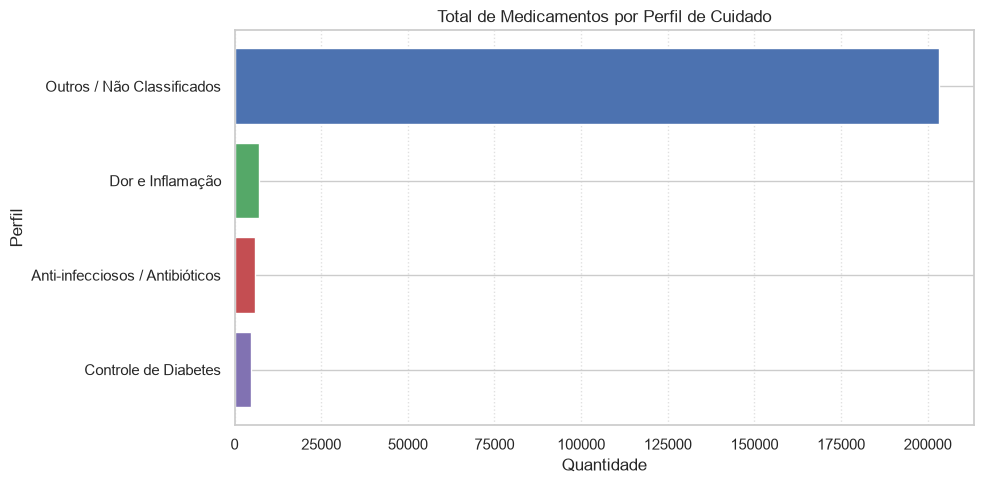

,Perfil de Cuidado,Total de Dispensações
0,Outros / Não Classificados,203192
1,Dor e Inflamação,7071
2,Anti-infecciosos / Antibióticos,5795
3,Controle de Diabetes,4757


In [23]:
contagem_perfis = df['perfil_cuidado'].value_counts().reset_index()
contagem_perfis.columns = ['Perfil de Cuidado', 'Total de Dispensações']

plt.figure(figsize=(10, 5))

cores = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#8C8C8C']

plt.barh(
    contagem_perfis['Perfil de Cuidado'], 
    contagem_perfis['Total de Dispensações'], 
    color=cores[:len(contagem_perfis)]
)

plt.title('Total de Medicamentos por Perfil de Cuidado', fontsize=12)
plt.xlabel('Quantidade')
plt.ylabel('Perfil')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

display(contagem_perfis)

### 3. Composição dos Medicamentos por Perfil
Detalhamento dos principais medicamentos associados a cada grupo de cuidado.

In [24]:
top_medicamentos = (
    df.groupby(['perfil_cuidado', coluna_med])
    .size()
    .reset_index(name='contagem')
    .sort_values(['perfil_cuidado', 'contagem'], ascending=[True, False])
    .groupby('perfil_cuidado')
    .head(5)
)

display(top_medicamentos)

,perfil_cuidado,material_descricao_complementar,contagem
1,Anti-infecciosos / Antibióticos,AMOXICILINA - 500 MG,2590
2,Anti-infecciosos / Antibióticos,AZITROMICINA 500 MG COMPRIMIDO,2403
0,Anti-infecciosos / Antibióticos,AMOXICILINA - 50 MG/ML,802
3,Controle de Diabetes,CANETA INSULINA,2897
4,Controle de Diabetes,"HIPODERMICA DE 1 ML C/ AGULHA 13 X 0,38 MM - I...",1860
5,Dor e Inflamação,DIPIRONA SÓDICA 500 MG COMPRIMIDO,7071
40,Outros / Não Classificados,20MG,34354
48,Outros / Não Classificados,25MG,17547
20,Outros / Não Classificados,100MG,15494
76,Outros / Não Classificados,5MG,13234


### 4. Percentual de Cada Linha de Cuidado
Visão da fatia de participação de cada grupo terapêutico no volume total dispensado.

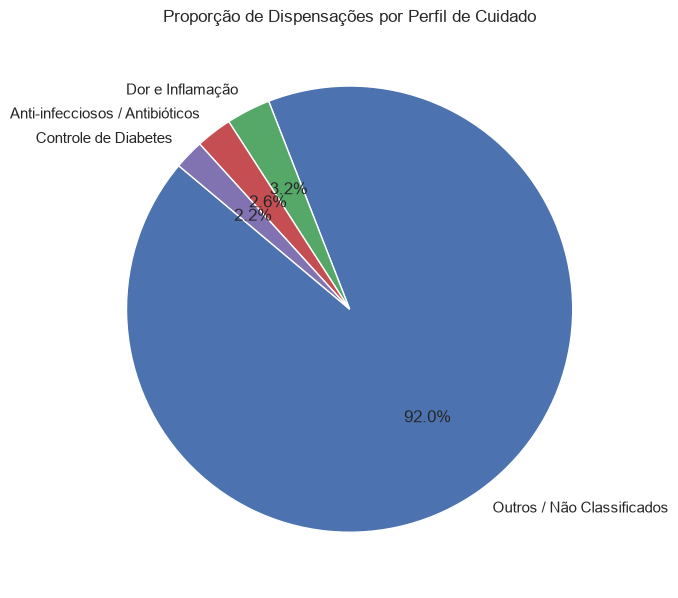

In [25]:
plt.figure(figsize=(7, 7))

plt.pie(
    contagem_perfis['Total de Dispensações'], 
    labels=contagem_perfis['Perfil de Cuidado'], 
    autopct='%1.1f%%', 
    startangle=140,
    colors=cores[:len(contagem_perfis)]
)

plt.title('Proporção de Dispensações por Perfil de Cuidado', fontsize=12)
plt.tight_layout()
plt.show()

### 5. Os 10 Medicamentos Mais Dispensados no Total
Ranking geral dos princípios ativos ou produtos mais retirados pela população.

C:\Users\esthe\AppData\Local\Temp\ipykernel_18704\3592303897.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


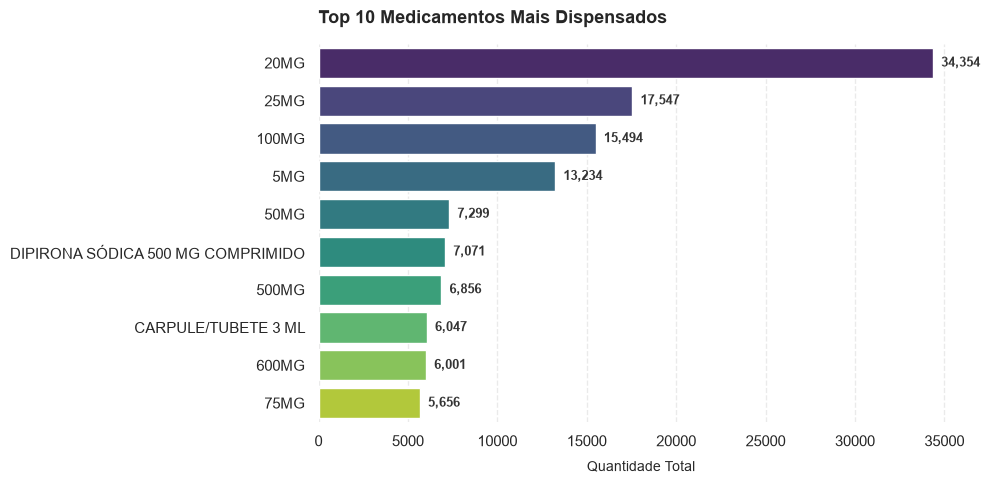

In [26]:
top_10_geral = df[coluna_med].value_counts().head(10).reset_index()
top_10_geral.columns = ['Medicamento', 'Quantidade']

plt.figure(figsize=(10, 5), dpi=100)

ax = sns.barplot(
    data=top_10_geral,
    x='Quantidade',
    y='Medicamento',
    palette='viridis'
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

for p in ax.patches:
    width = p.get_width()
    ax.annotate(
        f'{int(width):,}',
        xy=(width, p.get_y() + p.get_height() / 2),
        xytext=(6, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='#333333'
    )

plt.title('Top 10 Medicamentos Mais Dispensados', fontsize=13, fontweight='bold', pad=15, loc='left')
plt.xlabel('Quantidade Total', fontsize=10, labelpad=8)
plt.ylabel('')
plt.tight_layout()
plt.show()

### 6. Análise por Período ou Unidade de Saúde
Identificação de colunas de data ou local para avaliar variações temporais ou geográficas.

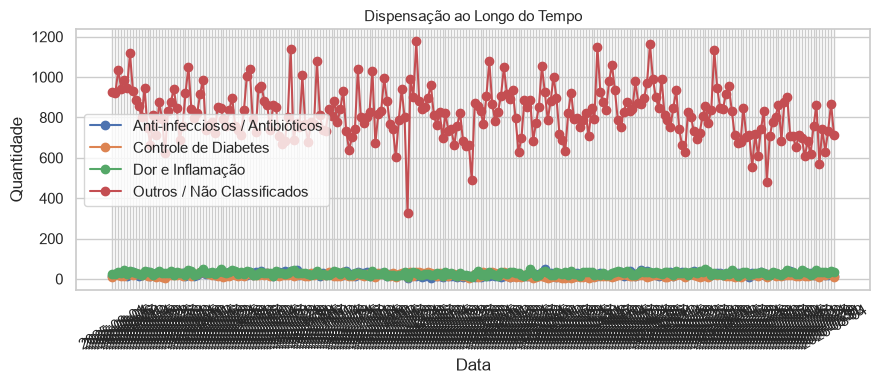

In [27]:
colunas_data = [col for col in df.columns if any(k in col.upper() for k in ['DATA', 'MES', 'ANO', 'PERIODO'])]

if colunas_data:
    col_data = colunas_data[0]
    tabela_tempo = pd.crosstab(df[col_data], df['perfil_cuidado'])
    
    plt.figure(figsize=(9, 4))
    
    for perfil in tabela_tempo.columns:
        plt.plot(tabela_tempo.index.astype(str), tabela_tempo[perfil], marker='o', label=perfil)
        
    plt.title('Dispensação ao Longo do Tempo', fontsize=11)
    plt.xlabel('Data')
    plt.ylabel('Quantidade')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()
else:
    print("Coluna de data não encontrada.")

### 7. Distribuição por Estabelecimento de Saúde
Comparação do volume e dos perfis de cuidado atendidos nas principais unidades de saúde.

<Figure size 1100x600 with 0 Axes>

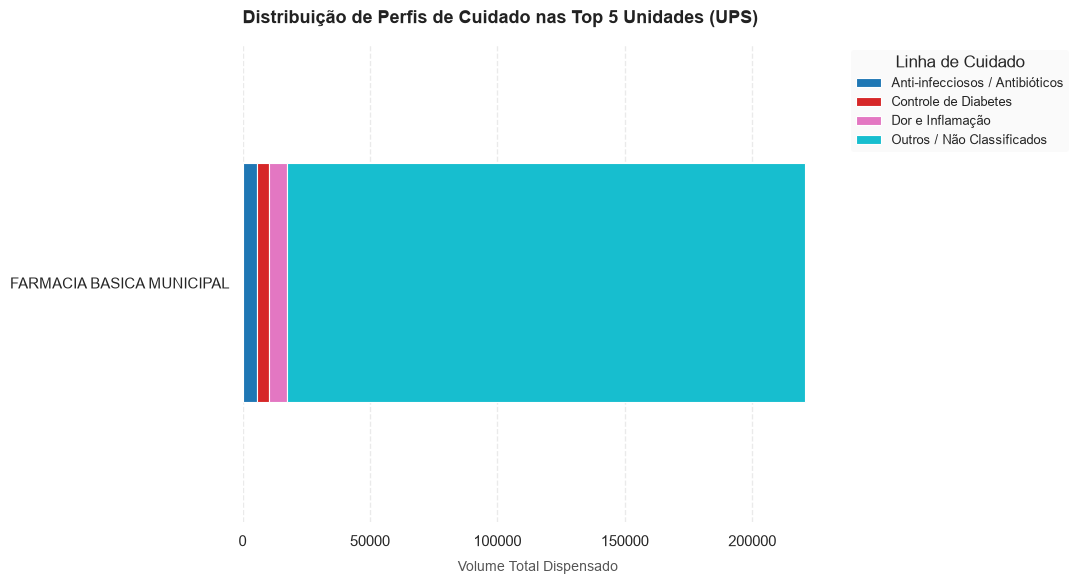

perfil_cuidado,Anti-infecciosos / Antibióticos,Controle de Diabetes,Dor e Inflamação,Outros / Não Classificados
ups_nome,,,,
FARMACIA BASICA MUNICIPAL,5795,4757,7071,203192


In [28]:
col_local = 'ups_nome'

top_locais = df[col_local].value_counts().head(5).index
df_top_locais = df[df[col_local].isin(top_locais)]

tabela_local = pd.crosstab(df_top_locais[col_local], df_top_locais['perfil_cuidado'])
tabela_local = tabela_local.loc[tabela_local.sum(axis=1).sort_values(ascending=True).index]

plt.figure(figsize=(11, 6), dpi=100)

ax = tabela_local.plot(
    kind='barh',
    stacked=True,
    figsize=(11, 6),
    colormap='tab10',
    edgecolor='white',
    linewidth=0.8
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

plt.title('Distribuição de Perfis de Cuidado nas Top 5 Unidades (UPS)', fontsize=13, fontweight='bold', pad=15, loc='left', color='#222222')
plt.xlabel('Volume Total Dispensado', fontsize=10, labelpad=8, color='#555555')
plt.ylabel('', fontsize=10)

plt.legend(
    title='Linha de Cuidado',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    facecolor='#f9f9f9',
    edgecolor='none',
    fontsize=9
)

plt.tight_layout()
plt.show()

display(tabela_local)